# Product Funnel Analytics on GA4 & Firebase Event Data

**Question:** where do users drop out of the journey, who drops out, and what would a product team change first?

Two real, public Google exports, queried with the same SQL you would run on a company's own GA4/Firebase BigQuery export:

| Source | Dataset | What it gives |
|---|---|---|
| GA4 (web) | `bigquery-public-data.ga4_obfuscated_sample_ecommerce` — Google Merchandise Store, Nov 2020–Jan 2021 | Purchase funnel, device/channel/country segments, revenue |
| Firebase (app) | `firebase-public-project.analytics_153293282` — Flood-It mobile game, Jun–Oct 2018 | Install → activation funnel, weekly retention cohorts, in-app purchase |

The funnel logic maps directly onto a digital-wallet journey (install → sign-up → KYC → first transaction): same event model, same SQL patterns, same decisions.

**Contents**
1. Setup & cost control
2. GA4: user-level purchase funnel
3. GA4: where the funnel breaks by device, channel and country
4. GA4: is the mobile gap real? (significance test)
5. GA4: time to convert
6. Firebase: install → activation funnel
7. Firebase: weekly retention cohorts
8. Firebase: what early behaviour predicts retention
9. Recommendations
10. Export for the dashboard

## 1. Setup
Runs in Google Colab. BigQuery free tier (1 TB/month of queries) covers everything here; each query scans only the columns it needs. You need a Google Cloud project ID (the free BigQuery sandbox is fine).

In [1]:
from google.colab import auth
auth.authenticate_user()

PROJECT_ID = "your-gcp-project-id"   # <- set this (BigQuery sandbox project is fine)

from google.cloud import bigquery
import pandas as pd, numpy as np, json
import matplotlib.pyplot as plt
from scipy import stats

bq = bigquery.Client(project=PROJECT_ID)

def q(sql, max_gb=20):
    # dry run first so we never scan more than expected
    job = bq.query(sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
    gb = job.total_bytes_processed / 1e9
    assert gb < max_gb, f"Query would scan {gb:.1f} GB"
    return bq.query(sql).to_dataframe()

GA4 = "`bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`"
FB  = "`firebase-public-project.analytics_153293282.events_*`"
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})

## 2. GA4: user-level purchase funnel
A **closed funnel**: a user counts at a step only if they also reached every earlier step, in order (first time they hit each step must come after the previous one). This is stricter than GA4's default report and avoids users "skipping" into checkout from a saved cart being counted as funnel progress.

In [2]:
FUNNEL_SQL = f'''
WITH firsts AS (
  SELECT
    user_pseudo_id,
    ANY_VALUE(device.category)          AS device,
    ANY_VALUE(traffic_source.medium)    AS medium,
    ANY_VALUE(geo.country)              AS country,
    MIN(IF(event_name='session_start',  event_timestamp, NULL)) AS t_session,
    MIN(IF(event_name='view_item',      event_timestamp, NULL)) AS t_view,
    MIN(IF(event_name='add_to_cart',    event_timestamp, NULL)) AS t_cart,
    MIN(IF(event_name='begin_checkout', event_timestamp, NULL)) AS t_checkout,
    MIN(IF(event_name='add_payment_info', event_timestamp, NULL)) AS t_payment,
    MIN(IF(event_name='purchase',       event_timestamp, NULL)) AS t_purchase,
    SUM(IF(event_name='purchase', ecommerce.purchase_revenue_in_usd, 0)) AS revenue
  FROM {GA4}
  WHERE _TABLE_SUFFIX BETWEEN '20201101' AND '20210131'
  GROUP BY user_pseudo_id
)
SELECT *
FROM firsts
'''
users = q(FUNNEL_SQL)
steps = ["s1_visit","s2_view","s3_cart","s4_checkout","s5_payment","s6_purchase"]
labels = ["Visit","View item","Add to cart","Checkout","Payment info","Purchase"]
# closed funnel: each step must happen after the previous one (NaN comparisons are False)
users[[c for c in users if c.startswith("t_")]] = users[[c for c in users if c.startswith("t_")]].astype(float)
u = users
u["s1_visit"]    = u.t_session.notna()
u["s2_view"]     = u.t_view.notna()
u["s3_cart"]     = u.s2_view & (u.t_cart > u.t_view)
u["s4_checkout"] = u.s3_cart & (u.t_checkout > u.t_cart)
u["s5_payment"]  = u.s4_checkout & (u.t_payment > u.t_checkout)
u["s6_purchase"] = u.s5_payment & (u.t_purchase > u.t_payment)
print(f"{len(users):,} users")

270,154 users


,step,users,% of visitors,step conversion %,lost at step
0,Visit,267116,100.0,NaN,NaN
1,View item,61252,22.9,22.9,205864.0
2,Add to cart,11114,4.2,18.1,50138.0
3,Checkout,4167,1.6,37.5,6947.0
4,Payment info,2903,1.1,69.7,1264.0
5,Purchase,2356,0.9,81.2,547.0


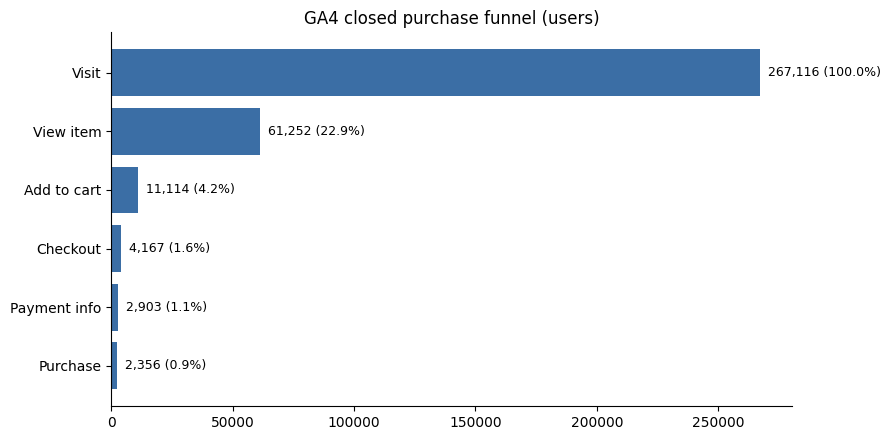

Biggest leak: 'Add to cart' — only 18.1% of the previous step continue (50,138 users lost).


In [3]:
def funnel_table(df):
    n = [int(df[s].sum()) for s in steps]
    t = pd.DataFrame({"step": labels, "users": n})
    t["% of visitors"] = t.users / t.users.iloc[0] * 100
    t["step conversion %"] = t.users / t.users.shift(1) * 100
    t["lost at step"] = (t.users.shift(1) - t.users)
    return t

ft = funnel_table(users)
display(ft.round(1))

fig, ax = plt.subplots()
ax.barh(ft.step[::-1], ft.users[::-1], color="#3b6ea5")
for y, (u, p) in enumerate(zip(ft.users[::-1], ft["% of visitors"][::-1])):
    ax.text(u, y, f"  {u:,} ({p:.1f}%)", va="center", fontsize=9)
ax.set_title("GA4 closed purchase funnel (users)")
plt.tight_layout(); plt.show()

worst = ft.iloc[1:].sort_values("step conversion %").iloc[0]
print(f"Biggest leak: '{worst.step}' — only {worst['step conversion %']:.1f}% of the previous step continue "
      f"({int(worst['lost at step']):,} users lost).")

## 3. GA4: where the funnel breaks by segment
Overall conversion hides the story. Compare step conversion by device, acquisition channel and top countries.

In [4]:
def seg_funnel(col, top=None, min_users=2000):
    g = users.copy()
    if top:
        keep = g[col].value_counts().head(top).index
        g = g[g[col].isin(keep)]
    rows = []
    for k, d in g.groupby(col):
        if len(d) < min_users: continue
        ft_ = funnel_table(d)
        r = {"segment": k, "visitors": len(d)}
        r.update({f"{a}": round(b, 2) for a, b in zip(ft_.step, ft_["step conversion %"])})
        r["visit→purchase %"] = round(d.s6_purchase.mean()*100, 2)
        r["revenue per visitor $"] = round(d.revenue.sum()/len(d), 2)
        rows.append(r)
    return pd.DataFrame(rows).drop(columns=["Visit"]).sort_values("visitors", ascending=False)

dev = seg_funnel("device");            display(dev)
med = seg_funnel("medium", top=6);     display(med)
cty = seg_funnel("country", top=8);    display(cty)

,segment,visitors,View item,Add to cart,Checkout,Payment info,Purchase,visit→purchase %,revenue per visitor $
0,desktop,156943,23.00,18.07,37.27,69.62,80.63,0.86,1.34
1,mobile,107136,22.81,18.31,37.83,69.77,81.93,0.89,1.35
2,tablet,6075,23.35,17.26,37.19,68.89,80.65,0.82,1.24


,segment,visitors,View item,Add to cart,Checkout,Payment info,Purchase,visit→purchase %,revenue per visitor $
4,organic,98750,21.76,16.66,36.18,68.43,80.68,0.72,1.02
1,(none),63640,22.51,18.66,36.32,68.05,79.82,0.82,1.22
2,<Other>,44725,20.59,16.47,35.54,62.94,81.07,0.61,0.81
5,referral,42382,25.39,19.64,40.10,72.12,81.83,1.16,1.87
3,cpc,13428,20.29,15.65,36.00,62.09,83.16,0.59,0.83
0,(data deleted),7229,50.15,27.49,44.08,84.42,83.33,3.87,7.86


,segment,visitors,View item,Add to cart,Checkout,Payment info,Purchase,visit→purchase %,revenue per visitor $
7,United States,118493,23.01,18.35,37.22,69.04,83.08,0.89,1.36
4,India,25367,23.13,17.83,36.59,69.84,78.79,0.82,1.38
0,Canada,20268,23.22,19.30,37.97,68.62,80.77,0.93,1.62
6,United Kingdom,8527,23.03,17.77,36.52,69.05,83.91,0.86,1.34
2,France,5381,22.64,16.93,37.25,71.05,83.33,0.84,1.24
5,Spain,5044,22.41,18.05,37.62,64.47,83.67,0.81,1.52
3,Germany,4866,21.17,16.88,40.70,74.29,71.15,0.76,1.09
1,China,4620,22.98,19.73,35.27,57.53,85.71,0.78,1.43


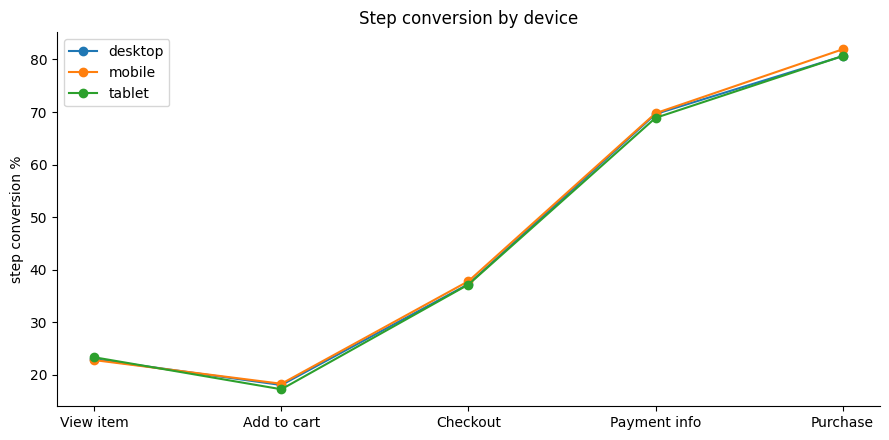

In [5]:
fig, ax = plt.subplots()
x = np.arange(len(labels)-1)
for _, r in dev.iterrows():
    ax.plot(x, [r[l] for l in labels[1:]], marker="o", label=r.segment)
ax.set_xticks(x); ax.set_xticklabels(labels[1:]); ax.set_ylabel("step conversion %")
ax.set_title("Step conversion by device"); ax.legend(); plt.tight_layout(); plt.show()

## 4. Is there a mobile vs desktop gap?
Two-proportion z-test on visit→purchase, plus the same test at the step where the device gap is largest.

**Result on this data: no meaningful gap.** Desktop 0.87% vs mobile 0.90% visit→purchase (p = 0.44), and no step differs significantly. That is a useful negative result: a "fix mobile checkout" project would not move conversion here — the losses are upstream, in product discovery (section 2), and differ by acquisition channel (section 3).

In [15]:
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

def compare(a, b, step_from, step_to, label):
    A = users[(users.device==a) & users[step_from]]; B = users[(users.device==b) & users[step_from]]
    x = [A[step_to].sum(), B[step_to].sum()]; n = [len(A), len(B)]
    z, p = proportions_ztest(x, n)
    ca = proportion_confint(x[0], n[0]); cb = proportion_confint(x[1], n[1])
    print(f"{label}: {a} {x[0]/n[0]*100:.2f}% [{ca[0]*100:.2f}–{ca[1]*100:.2f}] vs "
          f"{b} {x[1]/n[1]*100:.2f}% [{cb[0]*100:.2f}–{cb[1]*100:.2f}]  z={z:.2f}, p={p:.2g}")
    return dict(label=label, a=a, b=b, rate_a=x[0]/n[0], rate_b=x[1]/n[1], p=p)

tests = [compare("desktop","mobile","s1_visit","s6_purchase","Visit → purchase")]
# find step with the biggest relative desktop/mobile gap
gaps = {l: dev.set_index("segment").loc["desktop", l] - dev.set_index("segment").loc["mobile", l] for l in labels[1:]}
gap_step = max(gaps, key=lambda k: abs(gaps[k])); i = labels.index(gap_step)
tests.append(compare("desktop","mobile", steps[i-1], steps[i], f"{labels[i-1]} → {gap_step}"))


aov = users.loc[users.s6_purchase & (users.revenue>0), "revenue"].mean()
sig = [t["label"] for t in tests if t["p"] < 0.05]
print("Significant device gaps:", sig if sig else "none at the 5% level")

Visit → purchase: desktop 0.87% [0.82–0.91] vs mobile 0.90% [0.84–0.95]  z=-0.78, p=0.44
Payment info → Purchase: desktop 80.63% [78.74–82.53] vs mobile 81.93% [79.73–84.14]  z=-0.87, p=0.38
Significant device gaps: none at the 5% level


## 5. Time to convert
How long from first product view to purchase? Long tails mean the journey spans sessions — so re-engagement (email, push) matters, not just the checkout page.

       hours_view_to_purchase  minutes_checkout_to_purchase
count                  2356.0                        2356.0
mean                    119.5                         693.5
std                     275.5                        5248.7
min                       0.0                           0.5
25%                       0.2                           2.2
50%                       0.9                           3.8
75%                      72.8                           8.4
90%                     448.6                          52.9
max                    2143.0                      103630.3
51% of buyers purchase within an hour of first view; the rest come back later.


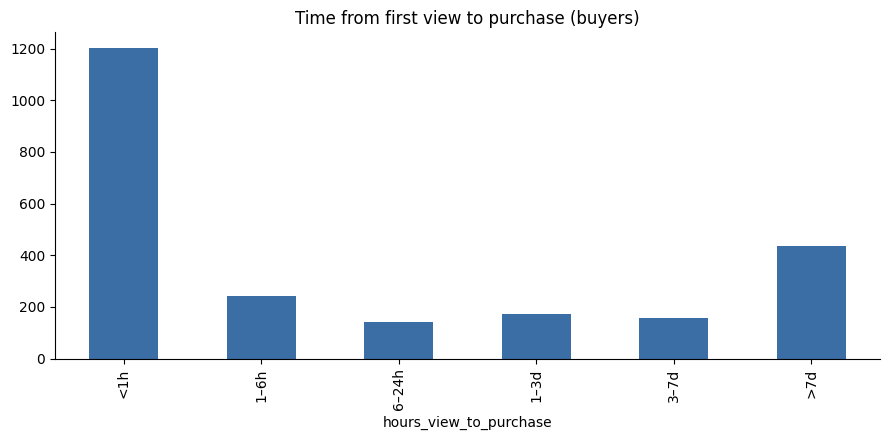

In [7]:
conv = users[users.s6_purchase].copy()
conv["hours_view_to_purchase"] = (conv.t_purchase - conv.t_view) / 3.6e9
conv["minutes_checkout_to_purchase"] = (conv.t_purchase - conv.t_checkout) / 6e7
same_session_share = (conv.hours_view_to_purchase < 1).mean()
print(conv[["hours_view_to_purchase","minutes_checkout_to_purchase"]].describe(percentiles=[.25,.5,.75,.9]).round(1))
print(f"{same_session_share*100:.0f}% of buyers purchase within an hour of first view; the rest come back later.")
bins = [0, 1, 6, 24, 72, 168, 1e9]; names = ["<1h","1–6h","6–24h","1–3d","3–7d",">7d"]
ttc = pd.cut(conv.hours_view_to_purchase, bins, labels=names).value_counts().reindex(names)
ttc.plot.bar(color="#3b6ea5", title="Time from first view to purchase (buyers)"); plt.tight_layout(); plt.show()

## 6. Firebase: install → activation funnel (mobile app)
The app equivalent of a wallet's install → sign-up → first transaction. For Flood-It: `first_open` → played a level → completed a level → returned on a later day → in-app purchase.

In [8]:
FB_SQL = f'''
WITH ev AS (
  SELECT user_pseudo_id, event_name, event_timestamp,
         PARSE_DATE('%Y%m%d', event_date) AS d,
         device.operating_system AS os, geo.country AS country
  FROM {FB}
),
u AS (
  SELECT user_pseudo_id,
    ANY_VALUE(os) AS os, ANY_VALUE(country) AS country,
    MIN(IF(event_name='first_open', d, NULL)) AS install_date,
    MIN(IF(event_name='first_open', event_timestamp, NULL)) AS t_install,
    MIN(IF(event_name LIKE 'level_start%', event_timestamp, NULL)) AS t_play,
    MIN(IF(event_name LIKE 'level_complete%', event_timestamp, NULL)) AS t_complete,
    MIN(IF(event_name='in_app_purchase', event_timestamp, NULL)) AS t_iap,
    COUNTIF(event_name LIKE 'level_complete%') AS levels_completed,
    COUNT(DISTINCT d) AS active_days,
    MAX(d) AS last_date
  FROM ev GROUP BY user_pseudo_id
)
SELECT * FROM u WHERE install_date IS NOT NULL
'''
app = q(FB_SQL)
app["returned_d1plus"] = app.active_days > 1
app["s1_install"]  = True
app["s2_play"]     = app.t_play > app.t_install
app["s3_complete"] = app.s2_play & (app.t_complete > app.t_play)
app["s4_return"]   = app.s3_complete & app.returned_d1plus
app["s5_purchase"] = app.s4_return & app.t_iap.notna()
asteps = ["s1_install","s2_play","s3_complete","s4_return","s5_purchase"]
alabels = ["Install","Started a level","Completed a level","Came back another day","In-app purchase"]
n = [int(app[s].sum()) for s in asteps]
aft = pd.DataFrame({"step": alabels, "users": n})
aft["% of installs"] = aft.users/aft.users.iloc[0]*100
aft["step conversion %"] = aft.users/aft.users.shift(1)*100
print(f"{len(app):,} installs"); display(aft.round(1))

4,319 installs


,step,users,% of installs,step conversion %
0,Install,4319,100.0,NaN
1,Started a level,2055,47.6,47.6
2,Completed a level,1178,27.3,57.3
3,Came back another day,719,16.6,61.0
4,In-app purchase,3,0.1,0.4


## 7. Weekly retention cohorts
Group users by install week; the share active in each following week. Read down a column to see if newer cohorts retain better (product getting better) or worse.

In [9]:
ACT_SQL = f'''
SELECT user_pseudo_id, DATE_TRUNC(PARSE_DATE('%Y%m%d', event_date), WEEK(MONDAY)) AS wk
FROM {FB} WHERE event_name IN ('user_engagement','session_start','screen_view')
GROUP BY 1,2
'''
act = q(ACT_SQL)
coh = app[["user_pseudo_id","install_date"]].copy()
coh["cohort"] = pd.to_datetime(coh.install_date).dt.to_period("W-SUN").dt.start_time
act["wk"] = pd.to_datetime(act.wk)
m = act.merge(coh, on="user_pseudo_id")
m["week_n"] = ((m.wk - m.cohort).dt.days // 7).astype(int)
m = m[m.week_n >= 0]
sizes = coh.groupby("cohort").size()
ret = (m.groupby(["cohort","week_n"]).user_pseudo_id.nunique().unstack()
         .div(sizes, axis=0) * 100).loc[:, :8]
ret = ret[sizes.reindex(ret.index) >= 200]       # drop tiny cohorts
ret.index = ret.index.strftime("%d %b")
display(ret.round(1).style.background_gradient(cmap="Blues", axis=None).format("{:.1f}"))
avg_curve = ret.mean()
print("Average retention: " + ", ".join(f"W{int(k)} {v:.1f}%" for k, v in avg_curve.items() if k in (1,2,4,8)))

week_n,0,1,2,3,4,5,6,7,8
cohort,,,,,,,,,
02 Jul,100.0,26.3,17.1,15.1,6.8,7.8,6.3,3.9,5.4
09 Jul,100.0,24.0,14.6,12.0,11.2,10.9,9.4,6.0,3.7
16 Jul,100.0,27.1,16.6,10.9,9.3,8.1,4.9,3.6,2.4
23 Jul,100.0,28.3,18.2,13.8,10.5,8.5,5.7,2.4,2.4
30 Jul,100.0,19.6,12.6,10.7,8.6,4.9,3.7,3.5,4.2
06 Aug,100.0,25.7,13.5,10.6,7.1,6.4,3.9,3.5,2.9
13 Aug,100.0,27.3,13.2,7.4,5.8,3.7,3.7,3.7,nan
20 Aug,100.0,18.8,10.0,7.5,4.2,4.2,2.9,nan,nan
27 Aug,100.0,13.7,10.1,5.9,8.5,4.2,nan,nan,nan


Average retention: W1 21.5%, W2 12.6%, W4 7.3%, W8 3.5%


## 8. What early behaviour predicts retention?
The 'aha moment' question: which first-day action separates users who stay from those who leave? Compare week-2+ retention for users who did vs didn't complete a level on install day.

,users,week2_retention
d0_band,,
0,1775,10.9
1–2,961,13.4
3–5,748,18.2
6–10,494,24.1
11+,341,23.8


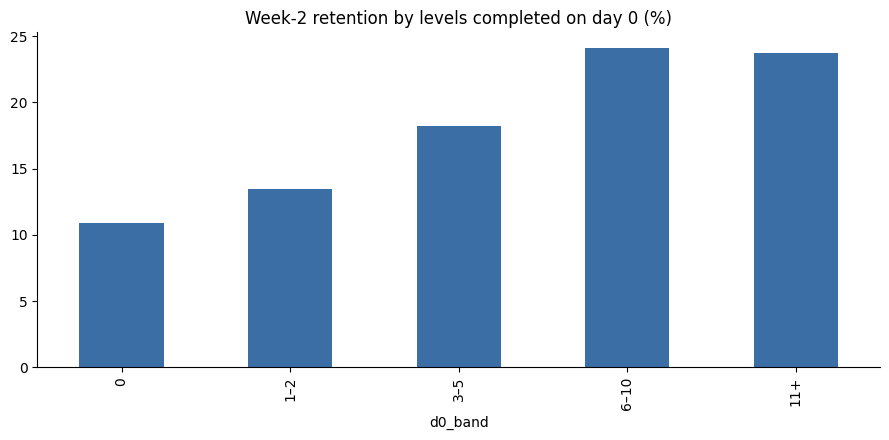

Correlation, not causation: engaged users complete more levels AND stay. The next step would be an experiment that helps new users reach the threshold faster.


In [10]:
DAY0_SQL = f'''
WITH f AS (SELECT user_pseudo_id, MIN(PARSE_DATE('%Y%m%d', event_date)) AS d0
           FROM {FB} WHERE event_name='first_open' GROUP BY 1)
SELECT f.user_pseudo_id,
  COUNTIF(e.event_name LIKE 'level_complete%' AND PARSE_DATE('%Y%m%d', e.event_date)=f.d0) AS d0_completes,
  COUNTIF(PARSE_DATE('%Y%m%d', e.event_date) BETWEEN DATE_ADD(f.d0, INTERVAL 7 DAY) AND DATE_ADD(f.d0, INTERVAL 13 DAY)) > 0 AS active_week2
FROM f JOIN {FB} e USING (user_pseudo_id)
GROUP BY 1
'''
d0 = q(DAY0_SQL)
d0["d0_band"] = pd.cut(d0.d0_completes, [-1,0,2,5,10,1e9], labels=["0","1–2","3–5","6–10","11+"])
aha = d0.groupby("d0_band", observed=True).agg(users=("user_pseudo_id","count"), week2_retention=("active_week2","mean"))
aha["week2_retention"] *= 100
display(aha.round(1))
aha.week2_retention.plot.bar(color="#3b6ea5", title="Week-2 retention by levels completed on day 0 (%)")
plt.tight_layout(); plt.show()
print("Correlation, not causation: engaged users complete more levels AND stay. "
      "The next step would be an experiment that helps new users reach the threshold faster.")

## 9. Findings & recommendations

1. **The funnel breaks at product discovery, not checkout.** Only 22.9% of visitors ever view a product, and only 18.1% of product viewers add to cart — the weakest step. Once users reach checkout, 69.7% add payment and 81.2% of those buy. Priority: search, navigation, merchandising and product pages, not the checkout form.
2. **Device is not the problem.** Desktop and mobile convert the same (0.87% vs 0.90%, p = 0.44). Don't fund a mobile-specific checkout project on this evidence.
3. **Channel quality differs 2×.** Referral traffic converts at 1.16% and earns $1.87 per visitor; paid search (cpc) converts at 0.59% and earns $0.83. Paid traffic lands but doesn't find products — check landing pages and keyword intent before raising spend. ("(data deleted)" is a GA4 obfuscation artefact, excluded from conclusions.)
4. **Half of buyers decide in one sitting, a fifth take over a week.** 51% purchase within an hour of first view, 18% after 7+ days — so browse/cart re-engagement is part of the funnel.
5. **App: the first step is the leak.** Only 47.6% of installers start a level. Users who complete 6+ levels on day one retain at 24% in week 2 vs 10.9% for those who complete none (correlation, not causation). Next step: an onboarding A/B test that gets new users into the first level faster.

**Digital-wallet translation:** product view → cart maps to sign-up → KYC; "starts a level" maps to "completes first transaction". The same closed-funnel SQL, segment cuts, significance tests and cohort tables apply unchanged to a wallet's Firebase export.

## 10. Export for the dashboard

In [16]:
out = {
  "ga4_funnel": ft[["step","users","% of visitors","step conversion %"]].round(2).fillna(0).to_dict("records"),
  "ga4_device": dev.round(2).to_dict("records"),
  "ga4_medium": med.round(2).to_dict("records"),
  "ga4_country": cty.round(2).to_dict("records"),
  "ga4_tests": [{k: (float(v) if isinstance(v,(np.floating,float)) else v) for k,v in t.items()} for t in tests],
  "ga4_time_to_convert": {k: int(v) for k, v in ttc.items()},
  "ga4_kpis": {"visitors": int(users.s1_visit.sum()), "buyers": int(users.s6_purchase.sum()),
               "conversion_pct": round(users.s6_purchase.mean()*100, 2),
               "revenue": round(float(users.revenue.sum()), 0), "aov": round(float(aov), 2),
               "same_session_pct": round(float(same_session_share*100), 1)},
  "app_funnel": aft.round(2).fillna(0).to_dict("records"),
  "app_retention": {"cohorts": list(ret.index), "weeks": [int(c) for c in ret.columns],
                    "values": [[None if pd.isna(v) else float(v) for v in row] for row in ret.round(1).values.tolist()]},
  "app_aha": [{"band": str(i), "users": int(r.users), "week2": round(float(r.week2_retention),1)} for i, r in aha.iterrows()],
  "app_kpis": {"installs": int(len(app)), "avg_w1": round(float(avg_curve.get(1, np.nan)),1),
               "avg_w4": round(float(avg_curve.get(4, np.nan)),1)},
}
json.dump(out, open("dashboard_data.json","w"), indent=1, default=str, allow_nan=False)
print(json.dumps(out["ga4_kpis"], indent=1), json.dumps(out["app_kpis"], indent=1))
from google.colab import files; files.download("dashboard_data.json")

{
 "visitors": 267116,
 "buyers": 2356,
 "conversion_pct": 0.87,
 "revenue": 362165.0,
 "aov": 86.29,
 "same_session_pct": 51.1
} {
 "installs": 4319,
 "avg_w1": 21.5,
 "avg_w4": 7.3
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>